# SPAM dataset: binary classification

**Task.** Predict whether an e-mail is spam from the frequencies of words and characters it contains.

**Dataset.** https://archive.ics.uci.edu/dataset/94/spambase (the copy used here is the one provided on Moodle).  
**Characteristics given in the assignment.** about 5,000 entries, 50 features, balanced classes.

This notebook applies the workflow implemented in `ml_workflow.py` to this dataset, shows the results and comments on them. It contains no machine-learning logic of its own: every step is a call to a function of the module. The second notebook of the project follows the same structure on the other dataset.

## Setup

Imports, configuration of the dataset and software environment.

In [2]:
# Reload ml_workflow automatically whenever the file is edited.
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Project root = first parent folder containing src/ml_workflow.py
# (works whether Jupyter starts in notebooks/ or at the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "ml_workflow.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import ml_workflow as mlw

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# Dataset
DATASET_NAME = "SPAM"
DATA_PATH = None  # TODO: match the name of the Moodle file
TARGET_COLUMN = None  # TODO: name of the label column in the file

# Reproducibility
RANDOM_STATE = mlw.RANDOM_STATE

# Display
pd.set_option("display.max_columns", None)

In [ ]:
mlw.get_environment_info()

{'python': '3.12.10',
 'numpy': '2.5.4',
 'pandas': '3.1.1',
 'scikit-learn': '1.9.1',
 'matplotlib': '3.11.2',
 'seaborn': '0.13.2'}

## 1. Import the dataset

Load the file and separate the features from the target.

In [ ]:
X, y = mlw.load_dataset(DATASET_NAME)

## 2. Clean and pre-process

Understand the data, clean it, and decide how it will be pre-processed.

### 2.1 Exploration

Size, feature types, missing values, class balance and correlations. This is where the specific difficulties of the dataset are identified.

#### Taille et nature des variables

In [6]:
print(f"{X.shape[0]} rows, {X.shape[1]} features")
feature_types = mlw.describe_feature_types(X)
display(feature_types["kind"].value_counts())
display(feature_types.round(2))

4601 rows, 57 features


kind
continuous    57
Name: count, dtype: int64

,kind,n_unique,min,max,zeros_%,skewness
word_freq_make,continuous,142,0.0,4.54,77.11,5.68
word_freq_address,continuous,171,0.0,14.28,80.48,10.09
word_freq_all,continuous,214,0.0,5.10,58.97,3.01
word_freq_3d,continuous,43,0.0,42.81,98.98,26.23
word_freq_our,continuous,255,0.0,10.00,62.01,4.75
word_freq_over,continuous,141,0.0,5.88,78.29,5.96
word_freq_remove,continuous,173,0.0,7.27,82.46,6.77
word_freq_internet,continuous,170,0.0,11.11,82.09,9.72
word_freq_order,continuous,144,0.0,5.26,83.20,5.23
word_freq_mail,continuous,245,0.0,18.18,71.70,8.49


**Commentaires.** 4 601 e-mails avec 57 variables numériques continues : 48 fréquences de mots (`word_freq_*`, en %), 6 fréquences de caractères (`char_freq_*`) et 3 statistiques sur les suites de majuscules (`capital_run_length_*`). Les variables ont souvent une médiane a 0 (84%) . Les échelles sont très différentes : les fréquences restent entre 0 et quelques dizaines, alors que `capital_run_length_total` monte à 15 841.

On a donc besoin d'une standardisation (sinon les variables `capital_run_length_*` écrasent les autres)

#### Valeurs manquantes et doublons

In [10]:
print("Missing values in X:", int(X.isna().sum().sum()))
print("Missing labels:", int(y.isna().sum()))
mlw.count_duplicates(X, y)

Missing values in X: 0
Missing labels: 0


{'duplicated_rows': 391, 'conflicting_rows': 6}

Les doublons sont **supprimés** au preprocessing (pas de sens d'avoir un meme mail 2x ou plus). On garde l'imputeur même si on n'a pas de valeurs qui manquent.

#### Répartition des classes

,count,proportion
Class,,
0,2788,0.605955
1,1813,0.394045


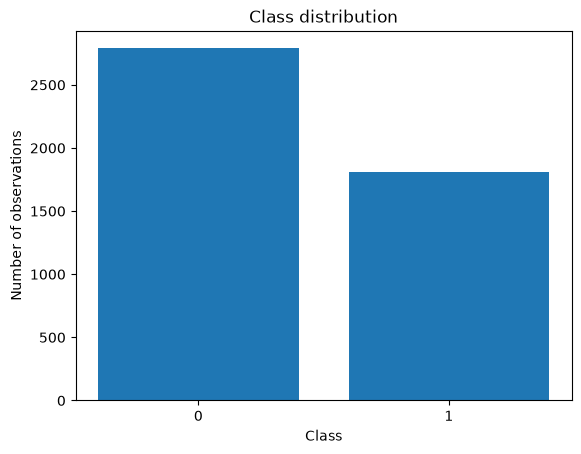

In [ ]:
display(mlw.get_class_distribution(y))
mlw.plot_class_distribution(y)
plt.show()

**Commentaires.** On a casiment la même proportion dans les deux classes. Mais on garde quand même un split **stratifié** pour garder ces proportions dans le train et le test.

#### Corrélations entre variables

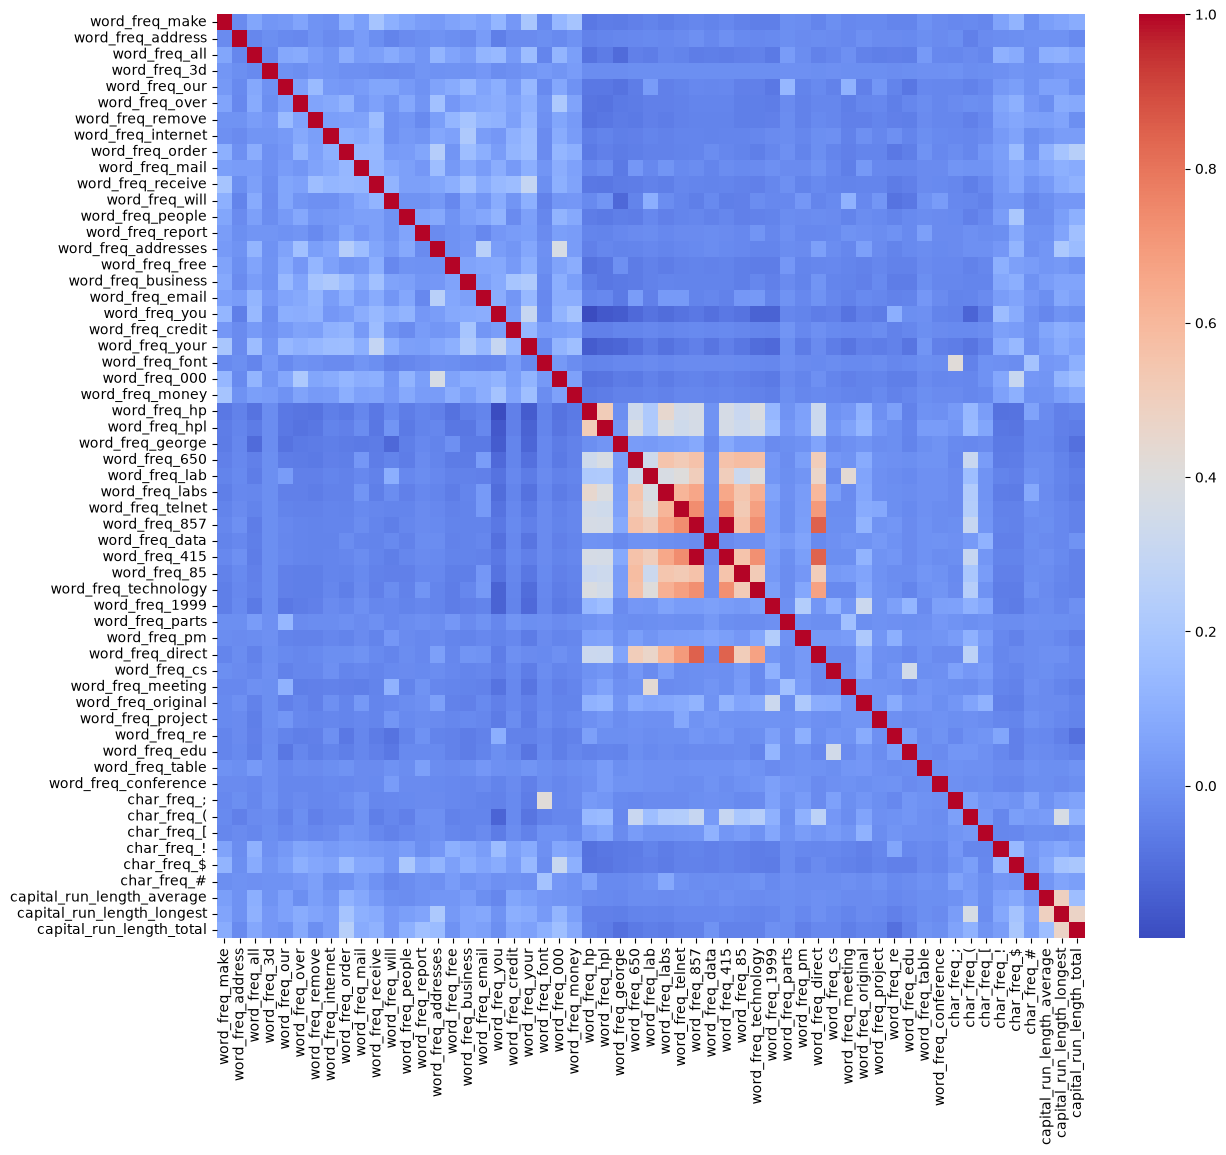

,feature_1,feature_2,abs_corr
0,word_freq_857,word_freq_415,1.00
1,word_freq_857,word_freq_direct,0.85
2,word_freq_415,word_freq_direct,0.85
3,word_freq_telnet,word_freq_857,0.74
4,word_freq_telnet,word_freq_415,0.74
5,word_freq_857,word_freq_technology,0.73
6,word_freq_415,word_freq_technology,0.73


In [8]:
# Correlation matrix, then the most correlated pairs.
fig, ax = plt.subplots(figsize=(14, 12) if X.shape[1] > 30 else (10, 8))
mlw.plot_correlation_matrix(X, ax=ax)
plt.show()

display(mlw.get_correlated_pairs(X, threshold=0.7).round(2))

**Commentaires.** La matrice est presque blanche : les variables sont **très peu corrélées** entre elles (|r| moyen ≈ 0,06). Il n'y que 7 paires dépassent 0,7, toutes dans un même groupe de mots (`word_freq_857` et `word_freq_415` à 1,0, puis `direct`, `telnet`, `technology`) (peut etre e-mails internes).

#### Lien entre les variables et la cible

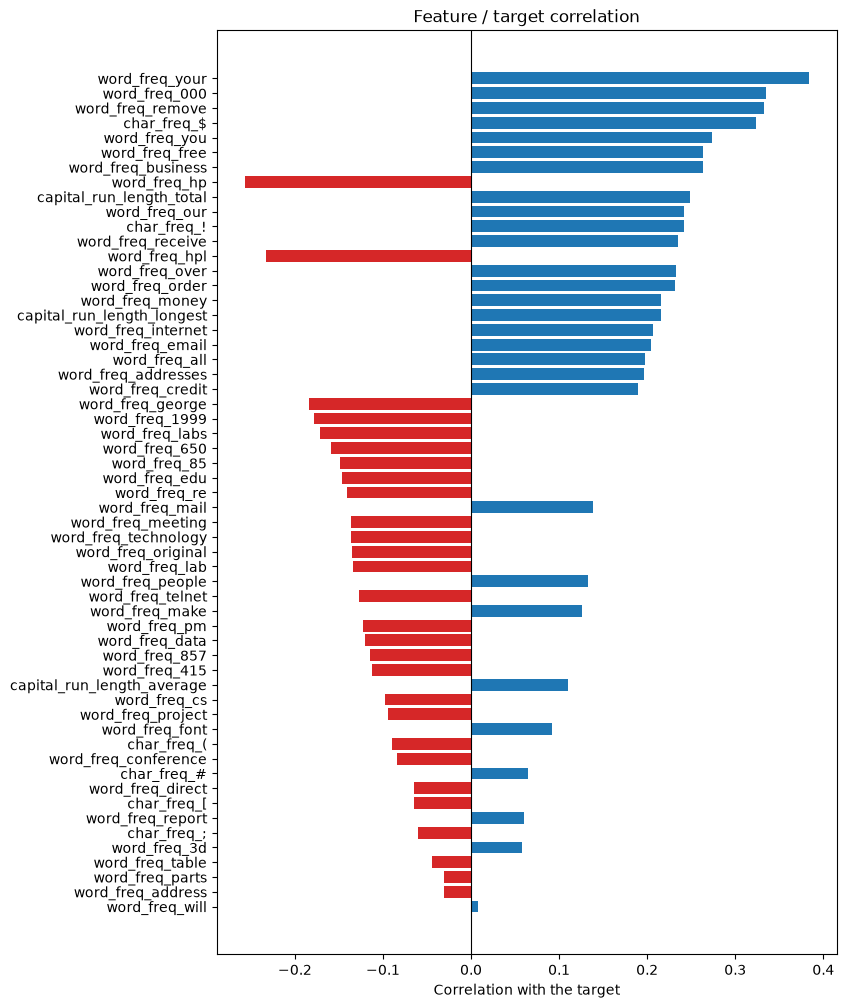

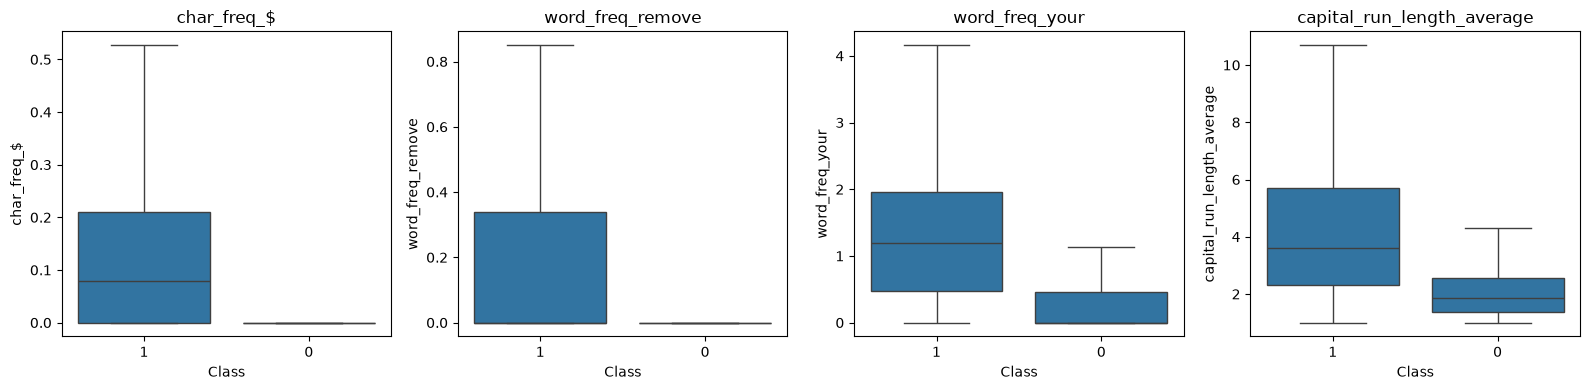

In [ ]:
# Corrélations linéaires avec direction
fig, ax = plt.subplots(figsize=(8, 12) if X.shape[1] > 30 else (8, 6))
mlw.plot_target_correlation(X, y, ax=ax)
plt.show()

# Distribution de quelques features discriminantes dans chaque classe
FEATURES_TO_PLOT = ["char_freq_$", "word_freq_remove", "word_freq_your", "capital_run_length_average"]
fig, axes = plt.subplots(1, len(FEATURES_TO_PLOT), figsize=(4 * len(FEATURES_TO_PLOT), 4))
for feature, ax in zip(FEATURES_TO_PLOT, axes):
    mlw.plot_feature_by_class(X, y, feature, ax=ax)
plt.tight_layout()
plt.show()

**Commentaires.** Aucune variable n'est fortement corrélée à la cible seule (max ≈ 0,38 pour `word_freq_your`) : c'est la **combinaison** de plusieurs variables qui permet de reconnaître un spam. 

**Synthèse des choix justifiés par l'exploration.**

| Constat | Choix |
|---|---|
| 391 doublons exacts (≈ 8 %) | suppression des doublons |
| aucune valeur manquante, distributions très asymétriques | imputeur médiane gardé par sécurité |
| échelles de 0–1 à plus de 15 000 | standardisation |
| 61 % / 39 % | split stratifié |
| beaucoup de variables peu liées à la cible | sélection de variables, information mutuelle |

### 2.2 Cleaning

Operations that learn nothing from the data (type conversion, duplicate rows, rows without a label), so they can safely run before the split.

In [11]:
n_before = len(X)
X, y = mlw.clean_dataset(X, y, drop_duplicates=True)
print(f"{n_before - len(X)} rows removed, {len(X)} left")
display(mlw.get_class_distribution(y))

391 rows removed, 4210 left


,count,proportion
Class,,
0,2531,0.601188
1,1679,0.398812


**Commentaires.** Les 391 doublons sont supprimés (4 210 e-mails restants). La répartition des classes est : 60 % / 40 %.

### 2.3 Pre-processing choices

Replacement of missing values (mean or median), centring and normalisation, and PCA.

These steps learn statistics from the data. To keep the test set unseen, they are only *chosen* here: they are *fitted* later, on the training set alone, as steps of the model pipeline (section 4).

In [12]:
# Pas de valeurs manquantes mais au cas ou
IMPUTE_STRATEGY = "median"

print("Missing values:", int(X.isna().sum().sum()))

Missing values: 0


## 3. Split into training and test sets

Stratified split with a fixed seed. The test set is not used again before section 5.

In [13]:
# Split Stratifié
X_train, X_test, y_train, y_test = mlw.split_dataset(
    X, y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, test: {X_test.shape}")
display(pd.concat(
    {"train": mlw.get_class_distribution(y_train),
     "test": mlw.get_class_distribution(y_test)}, axis=1
))

Train: (3368, 57), test: (842, 57)


train             test           
      count proportion count proportion
Class                                  
0      2025   0.601247   506    0.60095
1      1343   0.398753   336    0.39905

## 4. Train the models

Everything in this section uses the training set only.

### 4.1 Principal component analysis

Variance explained by the principal components, to decide whether PCA is useful here and how many components to keep.

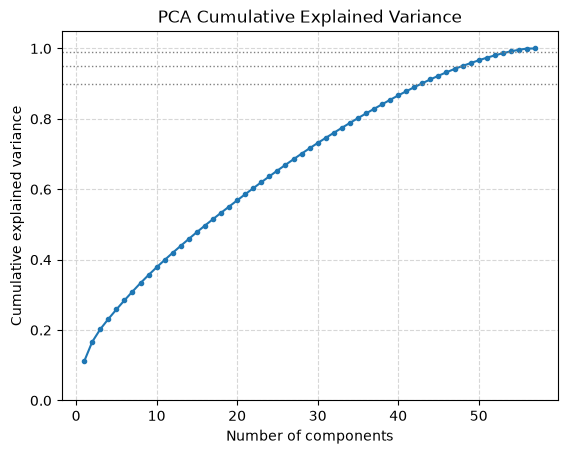

In [ ]:
# PCA : imputation médiane + standardisation
mlw.plot_pca_explained_variance(X_train)
for threshold in (0.90, 0.95, 0.99):
    plt.axhline(threshold, color="grey", linestyle=":", linewidth=1)
plt.show()

# Casiment pas de réduction de dimensions : pas util
PCA_COMPONENTS = None

**Commentaires.** Il faut 48 sur 57 features pour garder 95 % de la variance (43 pour 90 %). Comme vu dans l'exploration, les variables sont peu corrélées, donc la PCA réduirait très peu la dimension tout en rendant le modèle moins interprétable : **elle n'est pas utilisée**.

### 4.2 Feature selection

Rank the features, then choose the selection method and the number of features to keep.

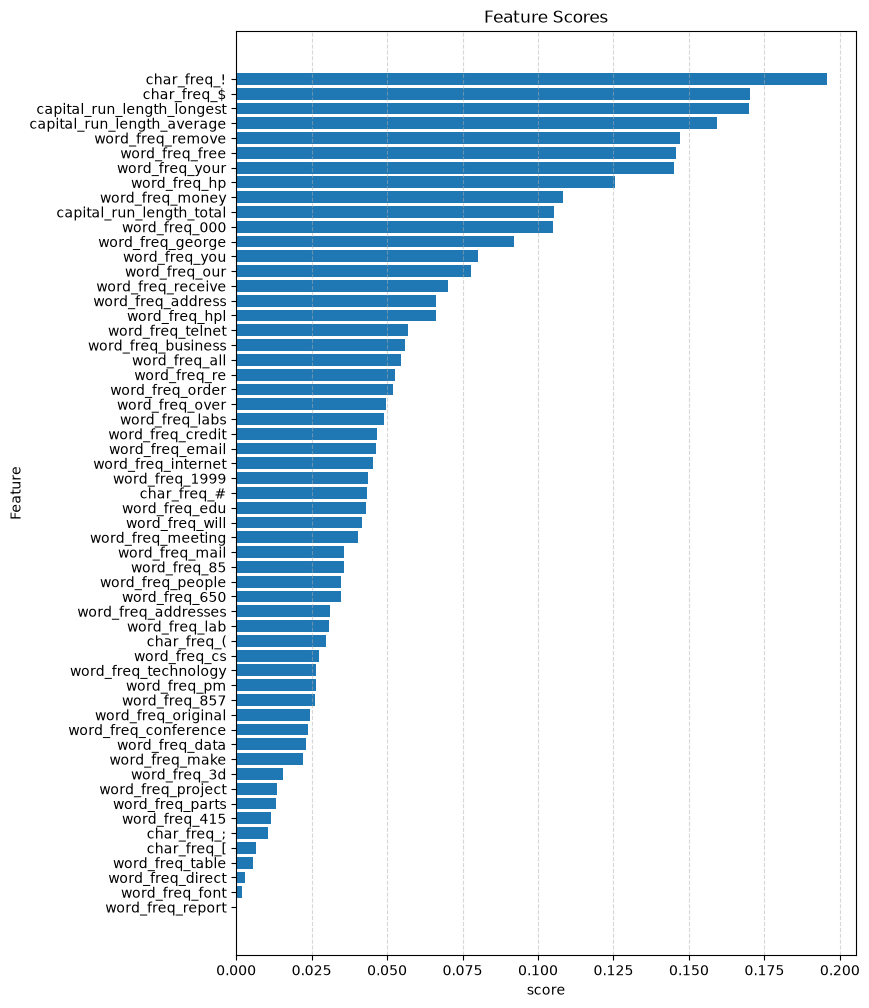

,"estimator estimator: objectThe base estimator from which the transformer is built.This can be both a fitted (if ``prefit`` is set to True)or a non-fitted estimator. The estimator should have a``feature_importances_`` or ``coef_`` attribute after fitting.Otherwise, the ``importance_getter`` parameter should be used.",RandomForestC...ndom_state=42)
,"threshold threshold: str or float, default=NoneThe threshold value to use for feature selection. Features whoseabsolute importance value is greater or equal are kept while the othersare discarded. If ""median"" (resp. ""mean""), then the ``threshold`` valueis the median (resp. the mean) of the feature importances. A scalingfactor (e.g., ""1.25*mean"") may also be used. If None and if theestimator has a parameter penalty set to l1, either explicitlyor implicitly (e.g, Lasso), the threshold used is 1e-5.Otherwise, ""mean"" is used by default.",-inf
,"max_features max_features: int, callable, default=NoneThe maximum number of features to select.- If an integer, then it specifies the maximum number of features to allow.- If a callable, then it specifies how to calculate the maximum number of features allowed. The callable will receive `X` as input: `max_features(X)`.- If `None`, then all features are kept.To only select based on ``max_features``, set ``threshold=-np.inf``... versionadded:: 0.20.. versionchanged:: 1.1 `max_features` accepts a callable.",40
,"prefit prefit: bool, default=FalseWhether a prefit model is expected to be passed into the constructordirectly or not.If `True`, `estimator` must be a fitted estimator.If `False`, `estimator` is fitted and updated by calling`fit` and `partial_fit`, respectively.",False
,"norm_order norm_order: non-zero int, inf, -inf, default=1Order of the norm used to filter the vectors of coefficients below``threshold`` in the case where the ``coef_`` attribute of theestimator is of dimension 2.",1
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a ``coef_``attribute or ``feature_importances_`` attribute of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case of:class:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all le

In [ ]:
# Information mutuelle :
scores = mlw.compute_feature_scores(X_train, y_train, method="mutual_info")
fig, ax = plt.subplots(figsize=(8, 12))
mlw.plot_feature_scores(scores, ax=ax)
plt.show()

# On garde les 40 variables les plus importantes selon une random forest.
# Choix validé par CV sur le train : F1 de 0,896 avec 40 variables contre 0,899 avec les 57.
SELECTION_METHOD = "model"
N_FEATURES = 40
selector = mlw.build_feature_selector(
    SELECTION_METHOD, n_features=N_FEATURES, random_state=RANDOM_STATE
)
selector

**Commentaires.** Les variables les plus utiles sont `!`, `$`, les majuscules et des mots comme *remove*, *free* ou *money* . Garder 40 variables sur 57 ne fait presque rien perdre (F1 0,896 contre 0,899) et retire les plus bruitées.

### 4.3 Models and pipelines

Le F1 de la classe spam prolonge le critère de la section 4.2. Il combine la précision des messages bloqués et le rappel des spams. On examinera aussi séparément les faux positifs, car ils font perdre du courrier légitime.

In [15]:
SCORING = "f1"
pipelines = {
    name: mlw.build_pipeline(model, impute_strategy=IMPUTE_STRATEGY, selector=selector,
                             pca_components=PCA_COMPONENTS, random_state=RANDOM_STATE)
    for name, model in mlw.get_models(random_state=RANDOM_STATE).items()
}

### 4.4 Cross-validation and hyperparameter tuning

La régression logistique fournit une référence additive. Un arbre peut capter des interactions par quelques règles, et le boosting combine plusieurs petits arbres. Les trois pipelines réapprennent les transformations et la sélection des variables dans chacun des cinq plis d’entraînement. On compare deux réglages de complexité par famille.

In [16]:
cv = mlw.build_cv_splitter(random_state=RANDOM_STATE)
cv_table, fitted_models = mlw.fit_candidates(
    pipelines, X_train, y_train, scoring=SCORING, cv=cv, compare_weights=False,
)
winner = cv_table.iloc[0]["model"]
display(cv_table.round(4))
print("Selected on training data:", winner)

,model,settings,mean_score,fold_sd,precision,recall
0,Boosting,max_leaf_nodes=31,0.9418,0.0077,0.9454,0.9382
1,Boosting,max_leaf_nodes=7,0.9287,0.0165,0.9422,0.9159
2,Logistic,C=1.0,0.8934,0.0179,0.9178,0.8705
3,Logistic,C=0.1,0.8863,0.0233,0.9213,0.8541
4,Tree,max_depth=8,0.8799,0.0059,0.9064,0.8555
5,Tree,max_depth=3,0.8434,0.0087,0.8672,0.8213


Selected on training data: Boosting


**Commentaire :** Le boosting à 31 feuilles maximales atteint un F1 moyen de 0,942 sur les cinq plis, devant la régression (0,893) et l’arbre seul (0,880). Les trois utilisent le même sélecteur de 40 variables. Je retiens donc le boosting avant d’ouvrir le jeu de test.

### 4.5 Final training and blocking threshold

La recherche a déjà réajusté le meilleur pipeline de chaque famille sur tout l’entraînement. Pour le boosting, on étudie aussi une politique de blocage plus stricte : atteindre 98 % de précision empirique et maximiser le rappel compatible avec cette cible. Le seuil est calculé sur des prédictions hors pli, avec les réglages retenus, puis figé avant le test.

In [17]:
fitted_models["Majority"] = mlw.majority_baseline(X_train, y_train)
features = mlw.get_selected_features(fitted_models[winner], X_train.columns)
print(f"{len(features)} selected features:", ", ".join(features))

# Freeze a second blocking policy using out-of-fold training predictions.
threshold, validation = mlw.select_blocking_threshold(fitted_models[winner], X_train, y_train, cv)
print(f"Threshold: {threshold:.6f} | OOF precision: {validation['precision']:.2%} | OOF recall: {validation['recall']:.2%}")

40 selected features: word_freq_make, word_freq_address, word_freq_all, word_freq_our, word_freq_over, word_freq_remove, word_freq_internet, word_freq_order, word_freq_mail, word_freq_receive, word_freq_will, word_freq_people, word_freq_free, word_freq_business, word_freq_email, word_freq_you, word_freq_credit, word_freq_your, word_freq_000, word_freq_money, word_freq_hp, word_freq_hpl, word_freq_george, word_freq_650, word_freq_labs, word_freq_data, word_freq_85, word_freq_technology, word_freq_1999, word_freq_meeting, word_freq_re, word_freq_edu, char_freq_;, char_freq_(, char_freq_!, char_freq_$, char_freq_#, capital_run_length_average, capital_run_length_longest, capital_run_length_total


Threshold: 0.939358 | OOF precision: 98.02% | OOF recall: 81.16%


## 5. Validate the models

Performance of the final models on the test set, which they have never seen.

### 5.1 Metrics

One row per model, one column per metric.

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
Logistic,0.9240,0.9188,0.9146,0.8929,0.9036,0.9722,0.9545
Tree,0.9062,0.8974,0.9054,0.8542,0.8790,0.9373,0.8827
Boosting,0.9406,0.9371,0.9307,0.9196,0.9251,0.9889,0.9770
Majority,0.6010,0.5000,0.0000,0.0000,0.0000,0.5000,0.3990


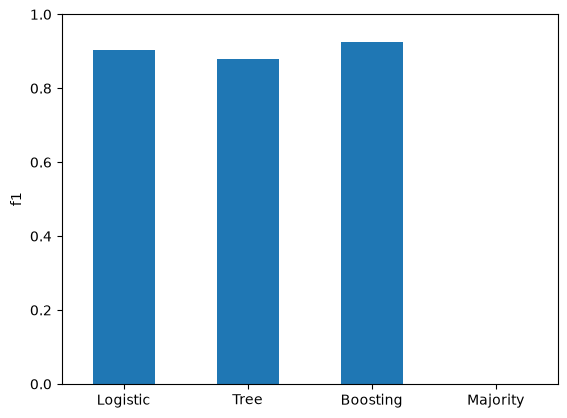

In [18]:
results = mlw.compare_models(fitted_models, X_test, y_test)
counts = ["TN", "FP", "FN", "TP"]
display(results.drop(columns=counts).round(4))
mlw.plot_model_comparison(results, metric=SCORING)
plt.show()

**Commentaire :** Sur les 842 e-mails réservés, le F1 du boosting atteint 0,925. La régression arrive à 0,904. La référence majoritaire classe correctement 60,1 % des messages tout en manquant les 336 spams : son exactitude donnerait une impression trompeuse de son utilité.

### 5.2 Confusion matrices

Kinds of errors made by each model.

,TN,FP,FN,TP
Logistic,478,28,36,300
Tree,476,30,49,287
Boosting,483,23,27,309
Majority,506,0,336,0


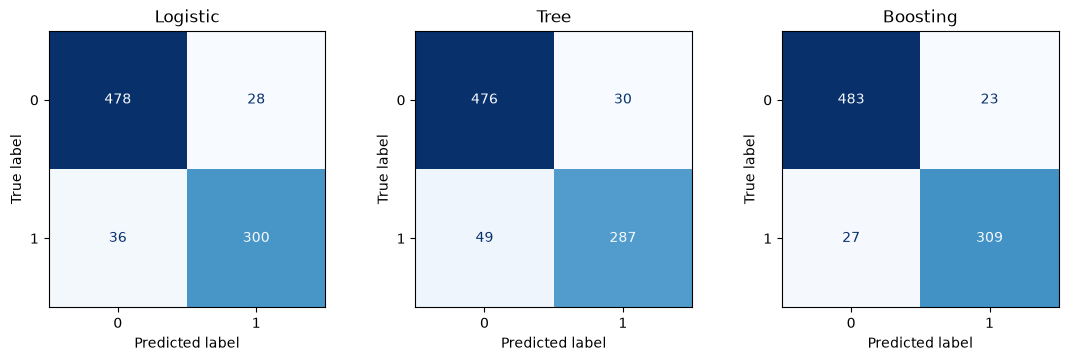

,precision,recall,f1
Default,0.9307,0.9196,0.9251
Strict,0.9853,0.7976,0.8816


,TN,FP,FN,TP
Default,483,23,27,309
Strict,502,4,68,268


In [19]:
display(results[counts].astype(int))
fig, axes = plt.subplots(1, len(pipelines), figsize=(11, 3.5), layout="constrained")
for ax, name in zip(axes, pipelines):
    mlw.plot_confusion_matrix(fitted_models[name], X_test, y_test, ax=ax)
    ax.set_title(name)
plt.show()

strict = mlw.evaluate_model(fitted_models[winner], X_test, y_test, threshold=threshold)
policies = pd.DataFrame({"Default": results.loc[winner], "Strict": strict}).T
display(policies[["precision", "recall", "f1"]].round(4))
display(policies[counts].astype(int))

**Commentaire :** Avec le seuil strict, la précision atteint 98,5 % sur le test. Le filtre bloque 4 messages légitimes au lieu de 23, mais laisse passer 68 spams au lieu de 27. Il épargne donc 19 messages légitimes au prix de 41 spams supplémentaires. Le F1 descend à 0,882.

### 5.3 ROC and precision-recall curves

Behaviour of each model over all decision thresholds.

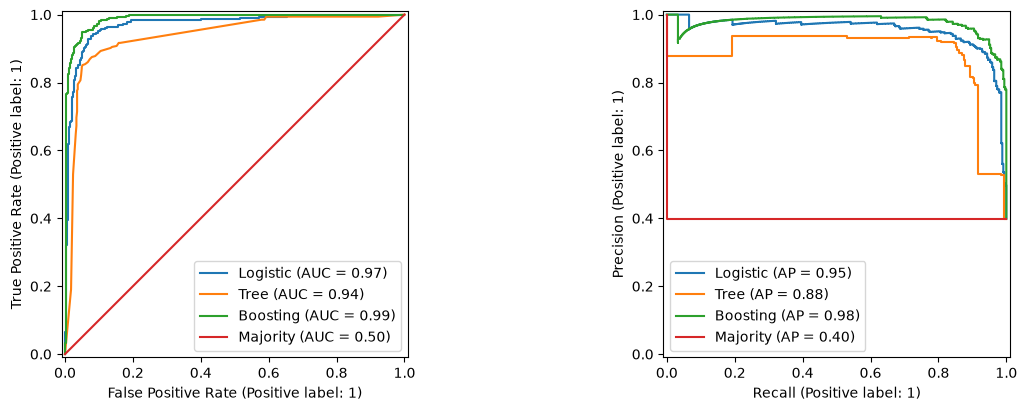

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
mlw.plot_roc_curves(fitted_models, X_test, y_test, ax=axes[0])
mlw.plot_precision_recall_curves(fitted_models, X_test, y_test, ax=axes[1])
plt.show()

**Commentaire :** Le boosting obtient une précision moyenne de 0,977, pour une proportion de spams de 0,399. Son classement permet plusieurs politiques de filtrage : la courbe précision-rappel montre le coût en rappel lorsque l’on exige davantage de précision.

## 6. Discussion and conclusion

Je retiens le boosting au seuil par défaut pour l’objectif F1 annoncé. Pour une suppression automatique, le seuil strict se justifie si perdre un message légitime coûte plus d’environ 2,2 fois le coût de laisser passer un spam (41/19 sur ce test). Ce rapport dépend de la boîte de réception et de l’usage.

L’évaluation porte sur les profils dédupliqués du corpus de 1999. Deux e-mails différents peuvent partager les mêmes 57 mesures. La déduplication change donc leur poids, et des mots liés aux expéditeurs d’origine peuvent perdre leur pouvoir discriminant dans une autre messagerie.

## 7. AI usage statement

Codex a aidé à compléter les sections 4.3 à 6 et les fonctions et tests correspondants. Les interprétations ont été vérifiées à partir des sorties de cette expérience. Voir le [README](../README.md).